# 1. Load the data


*   We will bring the loan Appllicant data
*   This data has details like income age and loan ammount

*   It is also tells us who repaid and who is fefaulted










In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df = pd.read_csv('credit_risk_dataset.csv')
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


# 2.Exploratory Data Analysis (EDA)

*   Here we simply look data before touching it
*   We want to understand it first work on it



### Basic Information About the Data

*   Check How many rows and columns we have
*   Check the data type of each column



In [6]:
df.shape
print(df.info)

<bound method DataFrame.info of        person_age  person_income person_home_ownership  person_emp_length  \
0              22          59000                  RENT              123.0   
1              21           9600                   OWN                5.0   
2              25           9600              MORTGAGE                1.0   
3              23          65500                  RENT                4.0   
4              24          54400                  RENT                8.0   
...           ...            ...                   ...                ...   
32576          57          53000              MORTGAGE                1.0   
32577          54         120000              MORTGAGE                4.0   
32578          65          76000                  RENT                3.0   
32579          56         150000              MORTGAGE                5.0   
32580          66          42000                  RENT                2.0   

           loan_intent loan_grade  loan_amn

### Missing Values

*   Find out which columns have empty or misssing values
*   This tells us where we may need to fix things later



In [7]:
df.isnull().sum()
df['loan_status'].unique()
df['loan_status'].value_counts()

,count
loan_status,
0,25473
1,7108


<Axes: xlabel='loan_status', ylabel='count'>

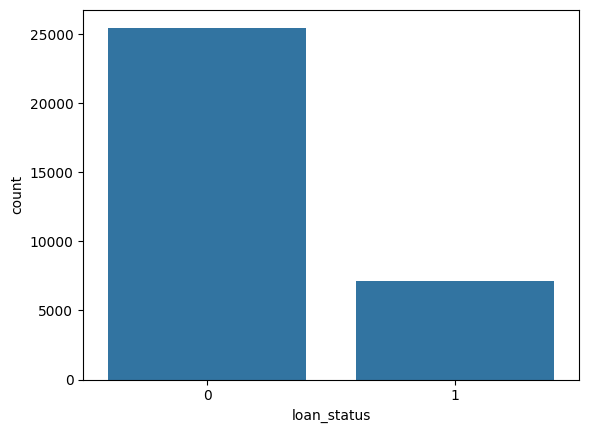

In [8]:
sns.countplot(x='loan_status',data=df)

### Outlier Check


*  Look for the values that is seem Impossible like age 144
*  These Are signs of bad entries



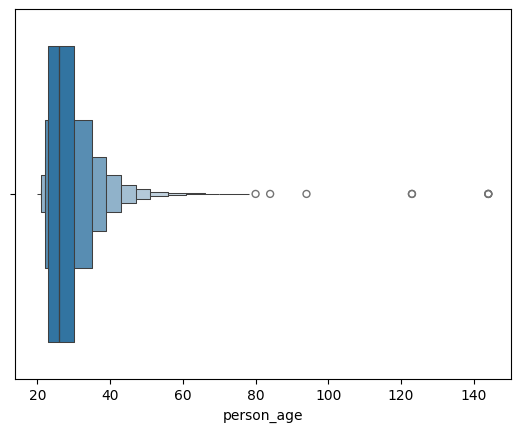

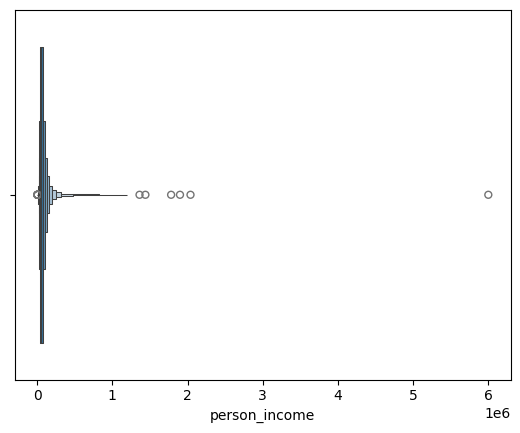

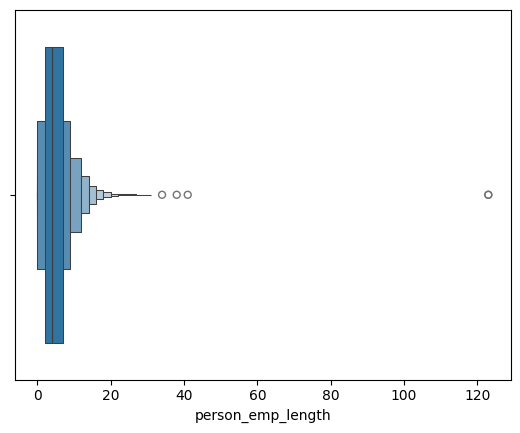

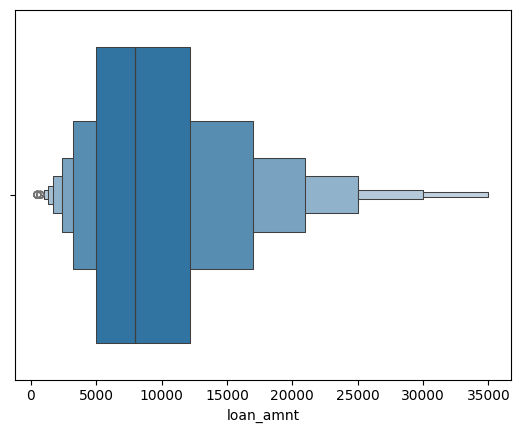

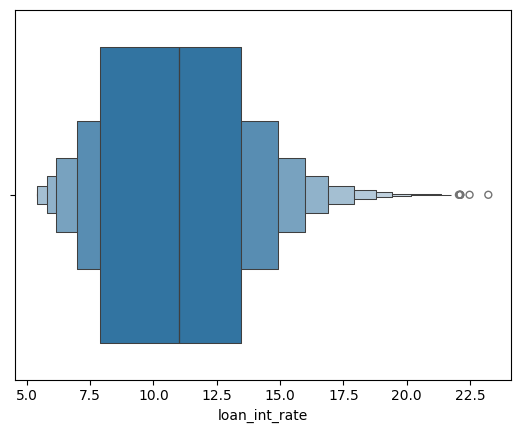

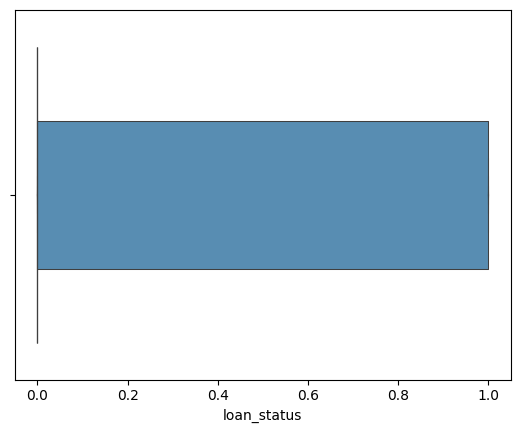

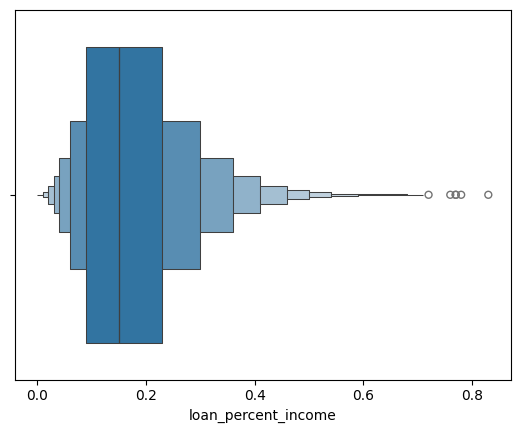

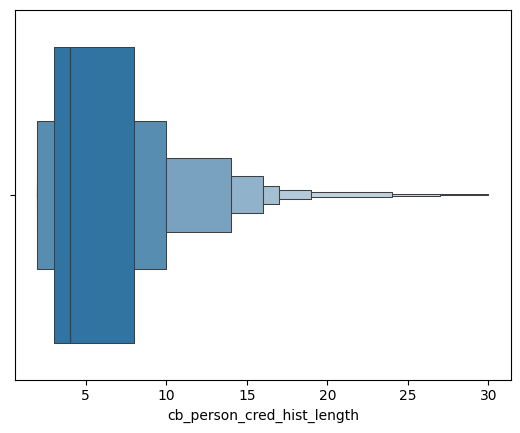

In [9]:
numerical_cols = df.select_dtypes(include=np.number).columns
for i in numerical_cols:
  sns.boxenplot(x=df[i])
  plt.show()

In [10]:
(df['person_age']>100).sum()

np.int64(5)

In [11]:
(df['person_emp_length']>60).sum()

np.int64(2)

### Correlation Check

*   See How strongly features are related to each other
*   This helps us spot repeated or linked information



<Axes: >

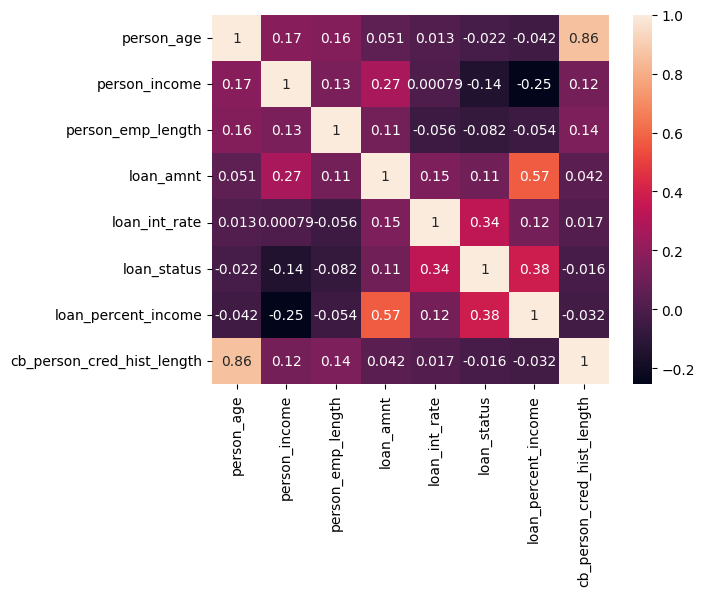

In [12]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

# 3.Data Validation & Outlier Handling

*   Here we clean the data properly
*   we remove duplicate rows
*   We remove rows with an impossible age and work experience
*   we remove rows with zero and negative income and loan amount

*   We check if the intrest rate looks realistic
*   we also flag rows where numbers do not add up correctly


In [13]:
df_copy = df.copy()
print(f"original Rows:{df_copy.shape[0]}")
#remove duplicate rows
df_copy.drop_duplicates(inplace=True)
print(f"Rows after removing duplicates:{df_copy.shape[0]}")

#remove ages below 18 or above 100
df_copy = df_copy[df_copy['person_age']>=18]
df_copy = df_copy[df_copy['person_age']<=100]

#remove employment length greater than age or extreme outliers(>=60)
df_copy = df_copy[df_copy['person_emp_length']<=df_copy['person_age']]
df_copy = df_copy[df_copy['person_emp_length']<=60]


#Remove the rows with zero or negative income and lone amount
df_copy = df_copy[df_copy['loan_amnt']>=0]


#Remove the unrealstic rate of intrest
df_copy = df_copy[df_copy['loan_int_rate']>=0]

original Rows:32581
Rows after removing duplicates:32416


# 4.Features Target & Train-Test Split

*   We Separate the data into input features and target
*   The target is whether the applicant default or not

*   We split the data into trainning part annd testing part
*   The model learns from the trainning part only






In [14]:
x = df_copy.drop('loan_status',axis=1)
y = df_copy['loan_status']

In [15]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

In [16]:
numeric_col = ['person_age','person_income','person_emp_length','loan_amnt','loan_int_rate','loan_percent_income','cb_person_cred_hist_length']
catagorical_col = ['person_home_ownership','loan_intent','loan_grade','cb_person_default_on_file']
#It will help us in pipeline and column trasformer

# 5.Handel Class Imbalance

*   Very few people actually default in this data
*   If we ignore this , model may just favour the majority class

*   We give more importance to the minority class during training
*   This helps the model acttually learn to spot defaulters

*   Adding class Weights is only applicable in the XGBoost  
*   In regration model it is build in







In [17]:
y_train.value_counts()
neg, pos = np.bincount(y_train)
scale_weights = neg/pos


# 6.Data Preprocessing -- Pipeline & Column Transformer

*   Raw data is not ready for a model directly

*   We need to prepare numeric and text columns diffrently
*   We will build a pipeline for each model


*   We will use column Trasformer to apply diffrent steps to different columns



### Pre processing for Logistic Regression

*   Fill Missing numeric values
*   Scale numeric values, since this model is a sensitive to scale

*   Convert catagory columns into numbers using one-hot encoding





In [18]:
#Logistic Regration : impute + scale + Scale Numeric + impute + One-Not-Encoding
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.compose import ColumnTransformer

preprocesor_lr= ColumnTransformer(
    transformers = [
         #pipeline- for numerical data
        ('num',Pipeline([
            ('imputer',SimpleImputer(strategy='median')),
            ('scaler',StandardScaler())
        ]),numeric_col),
         #Pipeline - for catagorical data
        ('cat',Pipeline([
            ('imputer',SimpleImputer(strategy="constant", fill_value = "Missing")),
            ('onehot',OneHotEncoder(handle_unknown='ignore'))
        ]),catagorical_col)
    ]
)


### Preprocessing for XGBoost

*   Fill missing numeric value

*   No scalling needed here, since tree models do not needed it.
*   Convert catagory columns into numbers using one-hot encoding




In [19]:
#XGBoost: Impute numeric only (No scalling), impute + one-hot encoding
preprocesor_xg= ColumnTransformer(
    transformers = [
         #pipeline- for numerical data
        ('num',Pipeline([
            ('imputer',SimpleImputer(strategy='median'))
        ]),numeric_col),
         #Pipeline - for catagorical data
        ('cat',Pipeline([
            ('imputer',SimpleImputer(strategy="constant", fill_value = "Missing")),
            ('onehot',OneHotEncoder(handle_unknown='ignore'))
        ]),catagorical_col)
    ]
)

# 7. Stratified Cross-Vaildation

*  One single train test split may not be reliable

*   We split the training data into five folds instead
*   Each fold keeps he same default vs repaid ratio


*   We check the model's score across all folds



In [20]:
from sklearn.model_selection import StratifiedKFold,cross_validate
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

scoring = {'roc_auc':'roc_auc','accuracy':'accuracy','precision':'precision','recall':'recall','f1':'f1'}

In [21]:
from sklearn.linear_model import LogisticRegression
lr_cv_pipeline = Pipeline([
    ('preprocessor', preprocesor_lr),
    ('classifier', LogisticRegression(class_weight='balanced',random_state=42))
])

In [22]:
#XGBoost Model
from xgboost import XGBClassifier
xgb_cv_pipeline = Pipeline([
    ('preprocessor', preprocesor_xg),
    ('classifier', XGBClassifier(n_estimator = 300, max_depth = 5, learning_rate = 0.1,scale_pos_weights=scale_weights,random_state=42))
])

In [23]:
for cv_name , pipe in [("Logistic Regression",lr_cv_pipeline),
                       ("XGBoost",xgb_cv_pipeline)]:
                       cv_results = cross_validate(pipe,x_train,y_train,cv=cv,scoring=scoring,n_jobs=-1)
                       print(cv_name)
                       print(f"ROC AUC: {cv_results['test_roc_auc'].mean()}")
                       print(f"Accuracy: {cv_results['test_accuracy'].mean()}")
                       print(f"Precision: {cv_results['test_precision'].mean()}")
                       print(f"Recall: {cv_results['test_recall'].mean()}")
                       print(f"F1: {cv_results['test_f1'].mean()}")


Logistic Regression
ROC AUC: 0.8723189618970608
Accuracy: 0.8125108614924017
Precision: 0.5482946003214749
Recall: 0.775959595959596
F1: 0.6425345950302089
XGBoost
ROC AUC: 0.9377150646951712
Accuracy: 0.9325758380377354
Precision: 0.9696710140795484
Recall: 0.7117171717171717
F1: 0.8208555877316922


In [24]:
cv_results

{'fit_time': array([0.70060253, 0.68313527, 0.49469399, 0.48775101, 0.29161286]),
 'score_time': array([0.09761047, 0.10083246, 0.09693027, 0.09956121, 0.05663371]),
 'test_roc_auc': array([0.93729678, 0.937871  , 0.94087145, 0.92947647, 0.94305962]),
 'test_accuracy': array([0.93377193, 0.93112525, 0.9341961 , 0.92564159, 0.93814433]),
 'test_precision': array([0.9673913 , 0.97338936, 0.96747967, 0.95780591, 0.98228883]),
 'test_recall': array([0.71919192, 0.7020202 , 0.72121212, 0.68787879, 0.72828283]),
 'test_f1': array([0.82502897, 0.8157277 , 0.82638889, 0.80070547, 0.83642691])}

## 8.Baseline Model - Logistic Regration

*   We start with simple model first.

*   This is our bench mark to beat
*   We train it and check its score on the test data


*   List item



In [25]:
baseline_model = Pipeline([
    ('preprocessor', preprocesor_lr),
    ('classifier', LogisticRegression(class_weight='balanced',random_state=42))
])
baseline_model.fit(x_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', random_state=42))])

Baseline Logistic Model Metrics
Accuracy: 0.82
Precision: 0.56
Recall: 0.78
F1: 0.65

Baseline Logistic Model Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      4462
           1       0.56      0.78      0.65      1237

    accuracy                           0.82      5699
   macro avg       0.74      0.80      0.76      5699
weighted avg       0.85      0.82      0.83      5699



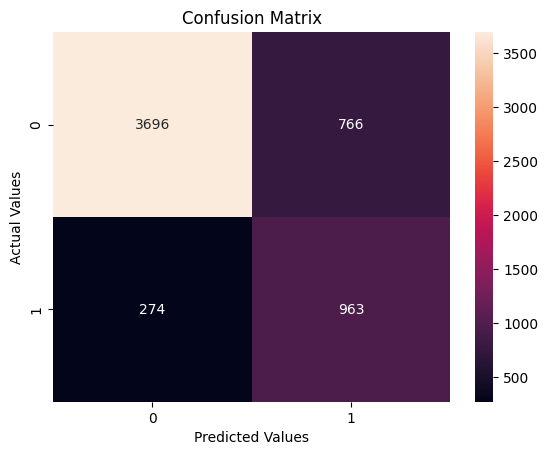

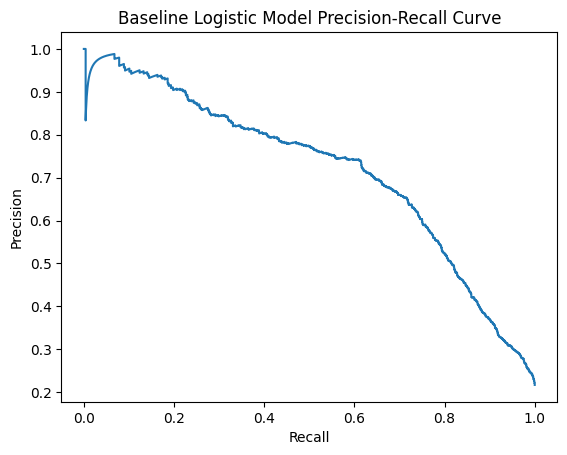

In [26]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report, precision_recall_curve, accuracy_score, precision_score, recall_score, f1_score

def evaluate_model(model_name, model, x_test, y_test, threshold=None):
    y_pred_prob = model.predict_proba(x_test)[:, 1]

    if threshold is not None:
        y_pred = (y_pred_prob > threshold).astype(int)
    else:
        y_pred = model.predict(x_test)

    # Metrics
    accuracy_s = accuracy_score(y_test, y_pred)
    precision_s = precision_score(y_test, y_pred)
    recall_s = recall_score(y_test, y_pred)
    f1_s = f1_score(y_test, y_pred)

    print(f"{model_name} Metrics")
    if threshold is not None:
        print(f"Best Threshold : {threshold}")
    print(f"Accuracy: {accuracy_s:.2f}")
    print(f"Precision: {precision_s:.2f}")
    print(f"Recall: {recall_s:.2f}")
    print(f"F1: {f1_s:.2f}")

    # Confusion Matrix & Classification Report
    cm = confusion_matrix(y_test, y_pred)
    class_report = classification_report(y_test, y_pred)
    print(f"\n{model_name} Classification Report:")
    print(class_report)

    # Plotting Confusion Matrix
    sns.heatmap(cm, annot=True, fmt='d')
    plt.xlabel("Predicted Values")
    plt.ylabel("Actual Values")
    plt.title("Confusion Matrix")
    plt.show()

    # Plotting Precision-Recall Curve
    precision, recalls, thresholds = precision_recall_curve(y_test, y_pred_prob)
    plt.plot(recalls, precision)
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(f"{model_name} Precision-Recall Curve")
    plt.show()

# Evaluate The Logistic Model
evaluate_model("Baseline Logistic Model", baseline_model, x_test, y_test)

# 9.Evaluation Helper function

*   We build one common function to check any model's performance

*   It will show accuracy, precision, recal,f1 and more
*   It will also show a confusion matrix and precision-recal curve




In [27]:
from sklearn.metrics import confusion_matrix,classification_report,ConfusionMatrixDisplay,precision_recall_curve,accuracy_score,precision_score,recall_score,f1_score,roc_auc_score
def evaluate_model(model_name,model,x_test,y_test,threshold= None):
  y_pred_prob = model.predict_proba(x_test)[:,1]

  if threshold:
    y_pred = (y_pred_prob>threshold).astype(int)
  else:
    y_pred = model.predict(x_test)

  #Metrices
  accuracy_s = accuracy_score(y_test,y_pred) #Overall Perfermance of Model
  precision_s = precision_score(y_test,y_pred)#of once i picked of how many were actually correct?
  recall_s = recall_score(y_test,y_pred)
  f1_s = f1_score(y_test,y_pred)
  print(f"{model_name} Metrics")
  print(f"Best Threshold : {best_threshold}")
  print(f"Accuracy: {accuracy_s:.2f}")
  print(f"Precision: {precision_s:.2f}")
  print(f"Recall: {recall_s:.2f}")
  print(f"F1: {f1_s:.2f}")
  print(f"{model_name} Classification Report:")
  print(class_report)
  #Confusion Matrix
  cm = confusion_matrix(y_test,y_pred)
  class_report = classification_report(y_test,y_pred)
  print("\nClassification Report:\n", class_report)
  #Plotting Confusion Matrix
  sns.heatmap(cm,annot=True,fmt='d')
  plt.xlabel("Predicted Values")
  plt.ylabel("Actual Values")
  plt.title("Confusion Matrix")
  plt.show()

  #Plotting ROC-AUC Curve
  precision , recalls , thresholds =precision_recall_curve(y_test,y_pred_prob)
  plt.plot(recalls, precision)
  plt.xlabel("Recall")
  plt.ylabel("Precision")
  plt.title(f"{model_name}Precision-Recall Curve")
  plt.show()

# 10.XGBoost Hyperparameter Tuning

*   Now we move to a stronger model , XGBoost

*   A model has many settings called hyperparameters
*   We search for the best combination of these settings


*  We use cross-validation while searching, so the result is reliable



In [28]:
xg_model = Pipeline([
    ('preprocessor', preprocesor_xg),
    ('classifier', XGBClassifier( scale_pos_weight=scale_weights,random_state=42,learning_rate = 0.1))
])
xg_model.fit(x_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='consta...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=None, n_jobs=None,
                               num_parallel_tree=None, ...))])

XGBoost Metrics
Accuracy: 0.92
Precision: 0.82
Recall: 0.80
F1: 0.81

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.95      0.95      4462
           1       0.82      0.80      0.81      1237

    accuracy                           0.92      5699
   macro avg       0.88      0.88      0.88      5699
weighted avg       0.92      0.92      0.92      5699



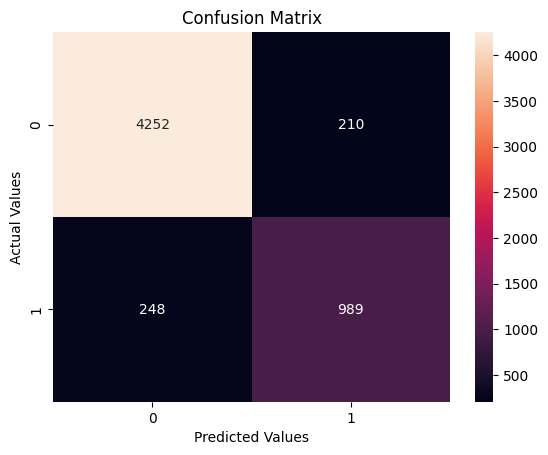

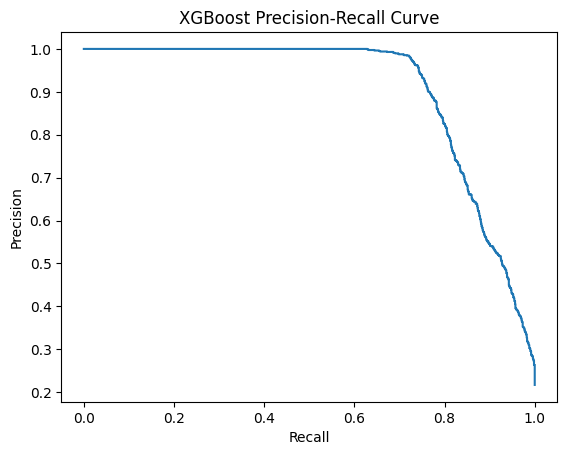

In [29]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report, precision_recall_curve, accuracy_score, precision_score, recall_score, f1_score

def evaluate_model(model_name, model, x_test, y_test, threshold=None):
    y_pred_prob = model.predict_proba(x_test)[:, 1]

    if threshold is not None:
        y_pred = (y_pred_prob > threshold).astype(int)
    else:
        y_pred = model.predict(x_test)

    # Metrics
    accuracy_s = accuracy_score(y_test, y_pred)
    precision_s = precision_score(y_test, y_pred)
    recall_s = recall_score(y_test, y_pred)
    f1_s = f1_score(y_test, y_pred)

    print(f"{model_name} Metrics")
    if threshold is not None:
        print(f"Best Threshold : {threshold}")
    print(f"Accuracy: {accuracy_s:.2f}")
    print(f"Precision: {precision_s:.2f}")
    print(f"Recall: {recall_s:.2f}")
    print(f"F1: {f1_s:.2f}")

    # Confusion Matrix & Classification Report
    cm = confusion_matrix(y_test, y_pred)
    class_report = classification_report(y_test, y_pred)
    print(f"\n{model_name} Classification Report:")
    print(class_report)

    # Plotting Confusion Matrix
    sns.heatmap(cm, annot=True, fmt='d')
    plt.xlabel("Predicted Values")
    plt.ylabel("Actual Values")
    plt.title("Confusion Matrix")
    plt.show()

    # Plotting Precision-Recall Curve
    precision, recalls, thresholds = precision_recall_curve(y_test, y_pred_prob)
    plt.plot(recalls, precision)
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(f"{model_name} Precision-Recall Curve")
    plt.show()

evaluate_model("XGBoost", xg_model, x_test, y_test)

In [30]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform,randint
param_grid = {
    'classifier__n_estimators': randint(150,600),
    'classifier__max_depth': randint(3,10),
    'classifier__learning_rate': uniform(0.01,0.5),
    'classifier__subsample': uniform(0.6,0.4),
    'classifier__colsample_bytree': uniform(0.5,0.5),
    'classifier__min_child_weight': randint(1,10),
    'classifier__gamma': uniform(0,5)
}

In [31]:
random_search = RandomizedSearchCV(
    xg_model,
    param_grid,
    n_iter=150,
    cv=cv,
    scoring='average_precision',
    n_jobs=-1,
    verbose=1
)
random_search.fit(x_train,y_train)

Fitting 5 folds for each of 150 candidates, totalling 750 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median'))]),
                                                                               ['person_age',
                                                                                'person_income',
                                                                                'person_emp_length',
                                                                                'loan_amnt',
                                                                                'loan_int_rate',
                                                                                'loan_percent_income',
                                                                                'cb_person_cred_hist_length...
                                        'classifier__min_child_weight': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7f56f5e10b90>,
                                        'classifier__n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7f56f63ebe00>,
                                        'classifier__subsample': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7f56f5e10050>},
                   scoring='average_precision', verbose=1)

In [32]:
random_search.best_params_

{'classifier__colsample_bytree': np.float64(0.8409550263263292),
 'classifier__gamma': np.float64(1.1852230780684436),
 'classifier__learning_rate': np.float64(0.06938627601366386),
 'classifier__max_depth': 6,
 'classifier__min_child_weight': 5,
 'classifier__n_estimators': 533,
 'classifier__subsample': np.float64(0.9056771166692411)}

In [33]:
print(f"Score after performing Tunning: {random_search.best_score_:.2f}")

Score after performing Tunning: 0.90


# 12.Optimizing the Classification Threshold

* The Model gives a probability, not a direct yes or no.

*   We decideda cut-off point to turn it into a decision.
*   We checked diffrent cut-off points and pick the best one.



XGBoost Metrics
Best Threshold : 0.9997289776802063
Accuracy: 0.78
Precision: 0.00
Recall: 0.00
F1: 0.00

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.78      1.00      0.88      4462
           1       0.00      0.00      0.00      1237

    accuracy                           0.78      5699
   macro avg       0.39      0.50      0.44      5699
weighted avg       0.61      0.78      0.69      5699



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_

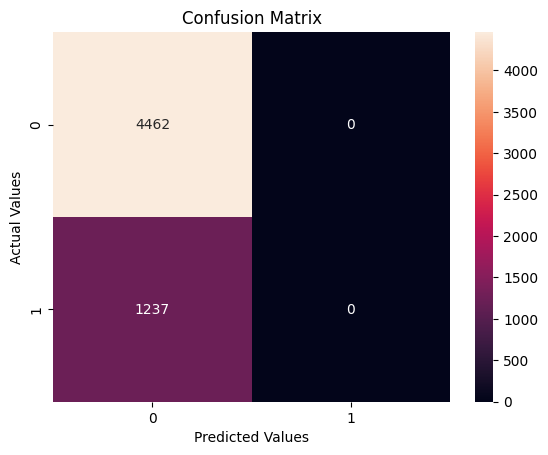

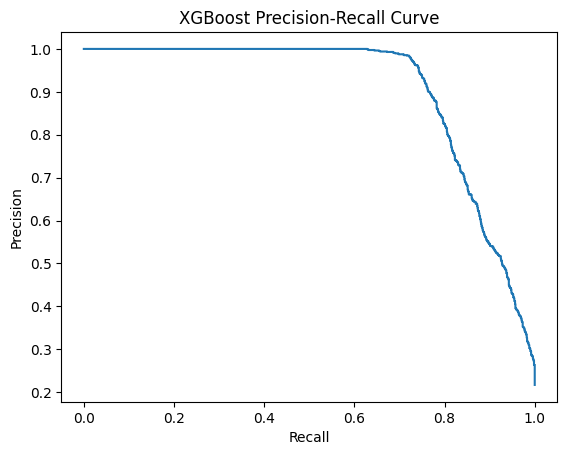

In [34]:
#Get the prob of class 1 from XGBoost
prob = xg_model.predict_proba(x_test)[:,1]
#For each threshold calculate Precision and Recall
precisions,recalls,thresholds = precision_recall_curve(y_test,prob)

#Calculate F1 score for each threshold
f1 = 2 *(precisions-recalls)/(precisions + recalls + 1e-9)
#Get the threshold that produce the highest f1-score
best = np.argmax(f1[:-1])
best_threshold= thresholds[best]
#Evaluate the XGBoost model using that threshold
evaluate_model("XGBoost",xg_model,x_test,y_test,best_threshold)

# 13.Probability Calibration

*   Sometimes a model's probability doesn't mean what it says

*   For Example, 30% risk should truly mean a 30% chance
*   We check this with a calibration plot


*  We fix it if the probabilities are off.



""""
### Methods by which by which we can fix the poorly calbrated model
1.Platt Scalling/ Sigmoid->Adjust the probabilities using sigmoid curve.

2.Isotonic Regration-> Learn a flexible mapping from old prob. - better prob(Non-linear calibration)

3.Temperature Scaling-> Adjust the confidence of neural network prediction using one temperature.
""""

In [64]:
#1.Calibration XGBoost Model
from sklearn.calibration import CalibratedClassifierCV,calibration_curve
best_model = random_search.best_estimator_
calibrated_model = CalibratedClassifierCV(best_model,
                                          method = "sigmoid",
                                          cv = 5
                                          )
calibrated_model.fit(x_train,y_train)

CalibratedClassifierCV(cv=5,
                       estimator=Pipeline(steps=[('preprocessor',
                                                  ColumnTransformer(transformers=[('num',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer(strategy='median'))]),
                                                                                   ['person_age',
                                                                                    'person_income',
                                                                                    'person_emp_length',
                                                                                    'loan_amnt',
                                                                                    'loan_int_rate',
                                                                                    'loan_percent_income',
                                                                                    'cb_person_cred_hist_length']),
                                                                                  ('cat',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer...
                                                                grow_policy=None,
                                                                importance_type=None,
                                                                interaction_constraints=None,
                                                                learning_rate=np.float64(0.06938627601366386),
                                                                max_bin=None,
                                                                max_cat_threshold=None,
                                                                max_cat_to_onehot=None,
                                                                max_delta_step=None,
                                                                max_depth=6,
                                                                max_leaves=None,
                                                                min_child_weight=5,
                                                                missing=nan,
                                                                monotone_constraints=None,
                                                                multi_strategy=None,
                                                                n_estimators=533,
                                                                n_jobs=None,
                                                                num_parallel_tree=None, ...))]))

In [65]:
#2.Get Probabilities
uncalibrated = xg_model.predict_proba(x_test)[:,1]
calibrated = calibrated_model.predict_proba(x_test)[:,1]

In [66]:
#3.Create Calibration Curve
actual_uncal, predicted_uncal = calibration_curve(y_test,uncalibrated,n_bins=10)

In [67]:
actual_cal, predicted_cal = calibration_curve(y_test,calibrated,n_bins=10)

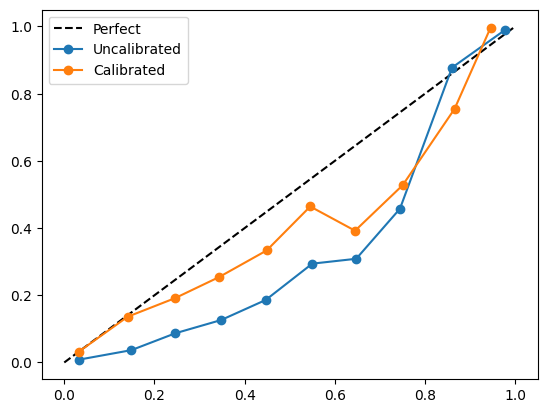

In [68]:
#4.plot
plt.plot([0,1],[0,1],"k--",label = "Perfect")
plt.plot(
    predicted_uncal,
    actual_uncal,
    "o-",
    label = "Uncalibrated"
)

plt.plot(
    predicted_cal,
    actual_cal,
    "o-",
    label = "Calibrated"
)
plt.legend()


# 14.SHAP Interpretation - Global &Local

*   Shap will update the things chanin by chain and ignore the unnessesary things



*   SHAP helps us understand why the model makes a decision
*   It is a way of explaning a "Black Box" modcel.



In [69]:
#install SHAP if not exists
!pip install shap
import shap

In [70]:
#2. Gete the Trained XGBoost classifier model out of the pipeline.
xgb_classifier = xg_model.named_steps['classifier']
#3.Trasform X_text using the same preprocessing used for training.
x_test_transformed = xg_model.named_steps['preprocessor'].transform(x_test)
#4.Get featured names after one-hot encoding, so plots are readable.
feature_names=xg_model.named_steps['preprocessor'].get_feature_names_out()\
#5.Convert to a dataframe for cleaner SHAP Plots
x_test_df = pd.DataFrame(x_test_transformed,columns=feature_names)
#6.Create SHAP explainner build for tree-based model
explainer = shap.TreeExplainer(xgb_classifier)
#7. Calculate SHAP values for every row in the test set
shap_values = explainer.shap_values(x_test_df)

### Global Explanation

*   This Shows which features matter most overall
*   It also shows if a feature increases or decreases risk



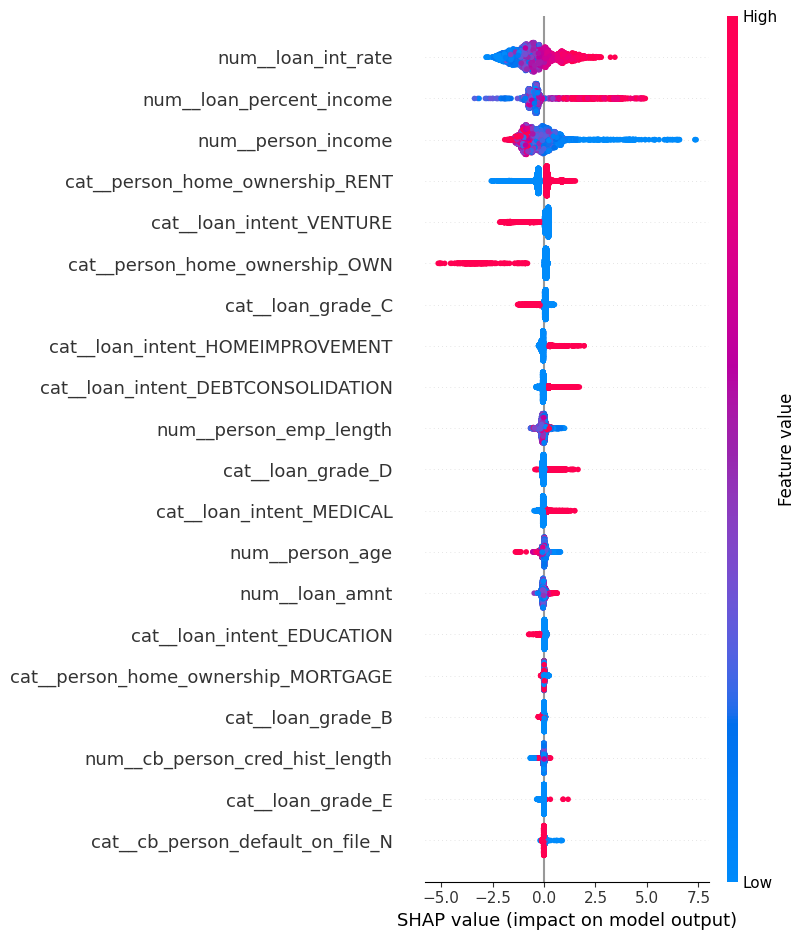

In [71]:
shap.summary_plot(shap_values,x_test_df)

### Local Exlanation

*   This shows why one specific application got their score
*   It breaks the score down feature by feature



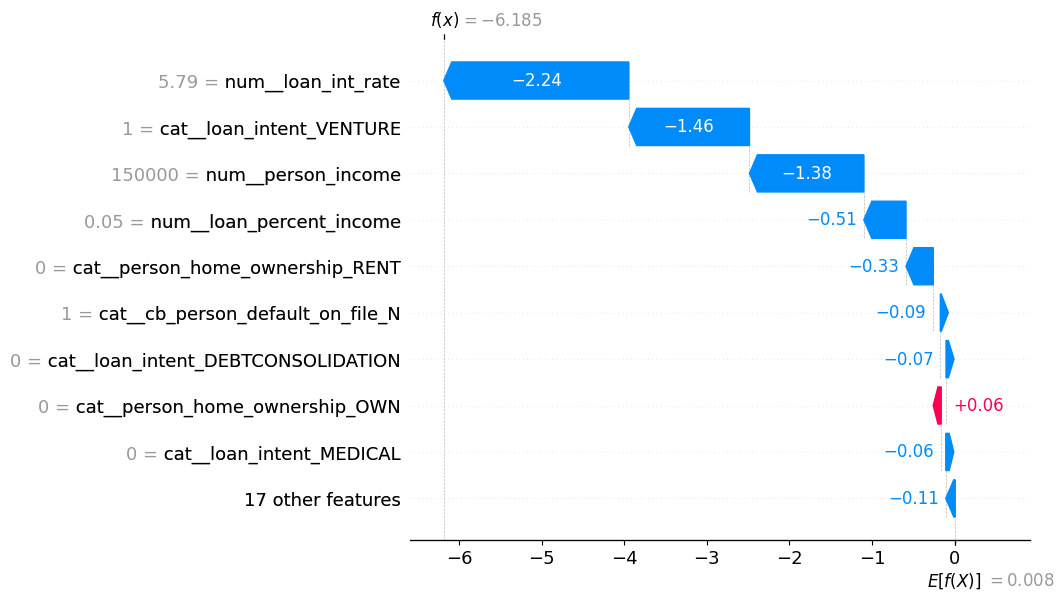

In [72]:
#1. Pick one row to explain, e.g:the 5th applicant in the test set
row_index = 5
#2. Draw a waterfall plot showing how each features pushed the prediction up or down
shap.plots.waterfall(
    shap.Explanation(
        values = shap_values[row_index],
        base_values = explainer.expected_value,
        data = x_test_df.iloc[row_index],
        feature_names = feature_names
    )
)

# 15. Analyswe the False Posiotive & False Negatives

*   The model will not be perfect.

*   False positives are safe people wrongly marked risky.
*   False negative are risky people wrongly marked safe

*   We study these cases to understand where the model struggles



In [73]:
#Get prediction from the best performing XGBoost model on the test set
y_pred = random_search.predict(x_test)

In [74]:
#Creating a dataframe to easily compare the actual and predicted values
result_df = x_test.copy()
result_df['actual'] = y_test
result_df['predicted'] = y_pred

In [75]:
#identify false positive: Model predict 1, but the actual value was 0
false_positive = result_df[(result_df['actual']==0) & (result_df['predicted']==1)]
#identify false positive: Model predict 0, but the actual value was 1
false_negative = result_df[(result_df['actual']==1) & (result_df['predicted']==0)]

In [76]:
print(f"False Positive: {len(false_positive)}")
print(f"False Negative: {len(false_negative)}")
#False Negative > False Positive

False Positive: 199
False Negative: 231


# 16.Save the Final Model

*   Once we are happy with the model, we save it.

*   We also save the settings it needs, like the chosen threshold
*   This saved file can now be used in real application



In [78]:
import joblib
joblib.dump(calibrated_model,"credit_risk_model.pkl")

['credit_risk_model.pkl']

In [84]:
joblib.dump(best_threshold,"best_threshold.pkl")

['best_threshold.pkl']

In [82]:
from sklearn.metrics import precision_recall_curve
import numpy as np
#1.Get probabilities from the CALIBIRATED model, not the old xg_model
calibrated_proba = calibrated_model.predict_proba(x_test)[:,1]
#2.Re-Run the same threshold search, now on the correct probability scale
precision, recall, thresholds = precision_recall_curve(y_test,calibrated_proba)
f1_scores = 2*(precisions*recalls)/(precisions+recalls+1e-9)
best_threshold = thresholds[np.argmax(f1_scores[:-1])]
print("New Threshold:",best_threshold)

New Threshold: 0.6470677104451883
